# Voice Activity Detection — Data Preprocessing & Feature Extraction

**Goal of this notebook:** prepare the LibriParty dataset and extract the two
feature sets needed for the two VAD branches of the project:

| Branch | Features needed |
|---|---|
| Classical VAD (rule-based threshold) | short-time energy + zero-crossing rate (ZCR) |
| Neural VAD (CRNN) | log-mel spectrogram |

This covers **stages 1–2** of the overall pipeline (raw audio → features).
No model training happens here — that's the next notebook. Everything below
is built so that a later `frame_labels` (ground truth) array lines up
frame-for-frame with both feature sets, which matters later for training
loss and for benchmarking classical vs. neural vs. Silero.

All frame-level outputs use **25 ms windows / 10 ms hop** at **16 kHz**, the
standard convention for speech VAD (and what SpeechBrain's own LibriParty
VAD recipe uses), so classical features, mel-spectrogram frames, and
ground-truth labels are always the same length and directly comparable.


In [37]:
# If running in a fresh environment (e.g. Google Colab), uncomment:
# !pip install librosa soundfile numpy matplotlib scipy

import os
import json
import glob

import numpy as np
import librosa
import librosa.display
import soundfile as sf
import matplotlib.pyplot as plt

np.random.seed(0)
plt.rcParams["figure.facecolor"] = "white"


In [38]:
# ---------------------------------------------------------------------
# Config — one place to change frame size / mel bins / etc.
# ---------------------------------------------------------------------
SAMPLE_RATE     = 16000   # Hz — all audio is resampled to this
FRAME_LENGTH_MS = 25      # analysis window length
HOP_LENGTH_MS   = 10      # hop between consecutive frames

FRAME_LENGTH = int(SAMPLE_RATE * FRAME_LENGTH_MS / 1000)   # 400 samples
HOP_LENGTH   = int(SAMPLE_RATE * HOP_LENGTH_MS   / 1000)   # 160 samples

# NOTE: n_fft is set equal to FRAME_LENGTH (not the usual 512/1024) so the
# mel-spectrogram lands on EXACTLY the same frame grid as the energy/ZCR
# features below. Librosa doesn't require n_fft to be a power of two.
N_FFT  = FRAME_LENGTH
N_MELS = 40   # matches the n_mels used in SpeechBrain's LibriParty VAD recipe

print(f"Frame length : {FRAME_LENGTH} samples ({FRAME_LENGTH_MS} ms)")
print(f"Hop length   : {HOP_LENGTH} samples ({HOP_LENGTH_MS} ms)")
print(f"Frame rate   : {SAMPLE_RATE / HOP_LENGTH:.1f} frames/sec")


Frame length : 400 samples (25 ms)
Hop length   : 160 samples (10 ms)
Frame rate   : 100.0 frames/sec


## 1. Dataset — LibriParty

**What it is.** LibriParty (SpeechBrain) is a pre-built collection of
simulated "party-like" recording sessions: LibriSpeech utterances from
multiple speakers mixed with MUSAN noise/music and reverberation, so the
speech/silence timing is realistic rather than clean read-speech with
robot-like pauses. Each session ships as a `.wav` file plus a matching
`.json` annotation giving the speech segments (who spoke, start/stop time).

**Getting it.** It's a direct download (not generated on the fly) — the
current links are listed in `recipes/LibriParty/VAD/README.md` in the
[SpeechBrain repo](https://github.com/speechbrain/speechbrain) (search
"LibriParty" there; the links occasionally move, so check the README rather
than hardcoding a URL here). You only need the LibriParty archive itself for
*this* notebook — MUSAN/CommonLanguage are only needed later, for
data-augmentation during actual model training.

**Annotation format.** SpeechBrain's JSON annotations aren't 100% uniform
across recipe versions, so the loader below is written defensively — it
handles the two schemas that show up in practice and normalizes either into
a plain list of `(start_sec, end_sec)` speech intervals. **Once you've
downloaded the real dataset, open one `.json` file and check its keys**
(`json.load(open(path)).keys()`); if the loader below doesn't recognize the
schema it will raise a clear error telling you what keys it saw — add a
branch for it, everything downstream is unaffected since it only depends on
the final `(start, end)` list.

**No real dataset here yet?** So the rest of this notebook — and the plots
below — run today, `generate_synthetic_libriparty_session()` builds a fake
session with the same *shape* as a real one: speech bursts (tones + noise
standing in for voiced/unvoiced sound) separated by silence gaps of varying
length, on a low-level noise floor, with a matching JSON annotation written
to disk. Flip `USE_SYNTHETIC_DEMO = False` and point at a real session once
downloaded — every cell after this one is unchanged either way.


In [ ]:
def load_libriparty_session(wav_path, annotation_path):
    '''
    Load one LibriParty session and its ground-truth speech/silence
    annotation. Returns (audio, sr, speech_segments) where speech_segments
    is a sorted, merged list of (start_sec, end_sec) tuples covering every
    moment ANY speaker is talking.
    '''
    audio, sr = librosa.load(wav_path, sr=SAMPLE_RATE, mono=True)

    with open(annotation_path, "r") as f:
        meta = json.load(f)

    speech_segments = []
    if "segments" in meta:
        # schema: {"segments": [{"start": .., "stop"/"end": ..}, ...]}
        for seg in meta["segments"]:
            start = seg.get("start", seg.get("start_time"))
            stop = seg.get("stop", seg.get("end", seg.get("end_time")))
            speech_segments.append((float(start), float(stop)))
    elif "speakers" in meta:
        # schema: {"speakers": {"spk1": [[start, stop], ...], ...}}
        for spk_segments in meta["speakers"].values():
            for start, stop in spk_segments:
                speech_segments.append((float(start), float(stop)))
    elif all(isinstance(value, list) for value in meta.values()):
        # LibriParty schema: {"speaker_id": [{"start": .., "stop": ..}, ...], ...}
        for speaker_segments in meta.values():
            for seg in speaker_segments:
                start = seg.get("start", seg.get("start_time"))
                stop = seg.get("stop", seg.get("end", seg.get("end_time")))
                speech_segments.append((float(start), float(stop)))
    else:
        raise KeyError(
            f"Unrecognised annotation schema in {annotation_path}. "
            f"Top-level keys found: {list(meta.keys())}. "
            "Inspect the file and add a branch to load_libriparty_session()."
        )

    # merge overlapping / touching speaker turns into one speech mask
    speech_segments.sort()
    merged = []
    for start, stop in speech_segments:
        if merged and start <= merged[-1][1]:
            merged[-1] = (merged[-1][0], max(merged[-1][1], stop))
        else:
            merged.append((start, stop))

    return audio, sr, merged

In [ ]:
wav_path = "LibriParty/dataset/train/session_0/session_0_mixture.wav"
json_path = "LibriParty/dataset/train/session_0/session_0.json"
session_tag = os.path.splitext(os.path.basename(wav_path))[0]
audio, sr, speech_segments = load_libriparty_session(wav_path, json_path)
session_label = session_tag

duration = len(audio) / sr
total_speech = sum(e - s for s, e in speech_segments)
total_pause = duration - total_speech

print(f"Session               : {session_label}")
print(f"Sample rate           : {sr} Hz")
print(f"Duration              : {duration:.2f} s")
print(f"Number of speech turns: {len(speech_segments)}")
print(f"Total speech time     : {total_speech:.2f} s ({100*total_speech/duration:.1f}%)")
print(f"Total pause time      : {total_pause:.2f} s ({100*total_pause/duration:.1f}%)")

Session               : session_0_mixture
Sample rate           : 16000 Hz
Duration              : 298.98 s
Number of speech turns: 12
Total speech time     : 180.97 s (60.5%)
Total pause time      : 118.01 s (39.5%)


## 2. Preprocessing

Three things happen here:

1. **Resample to 16 kHz, mono.** LibriSpeech (which LibriParty is built
   from) is already 16 kHz, but real-world recordings you might add later
   (e.g. your own speech-partner-app recordings) often aren't — `librosa.load(..., sr=16000, mono=True)`
   handles both resampling and stereo-to-mono in one call.
2. **Amplitude normalization.** Peak-normalizing every session to a common
   level means short-time energy is comparable *across* sessions/speakers,
   not just within one recording — otherwise a naturally quiet speaker
   could look like they're constantly pausing next to a loud one.
3. **Frame-level ground-truth labels.** The JSON annotation gives
   segment-level (start, end) times; we convert that into a 0/1 label
   *per 10 ms frame*, on the exact same frame grid the features below use.
   This is what later benchmarking (and CRNN training) compares
   predictions against, and it's also what lets us shade "true pause"
   regions on every plot below.


In [41]:
def resample_and_mono(path, target_sr=SAMPLE_RATE):
    '''Load an arbitrary raw audio file, forcing mono + target_sr.
    (load_libriparty_session / the synthetic generator already return
    mono 16 kHz audio — use this on any *other* raw file you bring in.)'''
    audio, sr = librosa.load(path, sr=target_sr, mono=True)
    return audio, sr


def peak_normalize(audio, target_peak=0.95):
    '''Scale so the loudest sample hits target_peak. Preserves relative
    dynamics within the recording while putting every session on a
    comparable amplitude scale and avoiding clipping.'''
    peak = np.max(np.abs(audio)) + 1e-9
    return audio * (target_peak / peak)


def segments_to_frame_labels(speech_segments, n_frames, sr=SAMPLE_RATE, hop_length=HOP_LENGTH):
    '''Turn (start_sec, end_sec) speech intervals into a per-frame 0/1
    ground-truth array (1 = speech, 0 = silence/pause), aligned to the same
    10 ms frame grid as the energy/ZCR/mel-spectrogram features.'''
    labels = np.zeros(n_frames, dtype=np.int32)
    frame_times = librosa.frames_to_time(np.arange(n_frames), sr=sr, hop_length=hop_length)
    for start, end in speech_segments:
        labels[(frame_times >= start) & (frame_times < end)] = 1
    return labels, frame_times


audio = peak_normalize(audio)

n_frames = 1 + (len(audio) - FRAME_LENGTH) // HOP_LENGTH
frame_labels, frame_times = segments_to_frame_labels(speech_segments, n_frames, sr)

print(f"Total frames @ {HOP_LENGTH_MS} ms hop : {n_frames}")
print(f"Speech frames                  : {frame_labels.sum()} ({100*frame_labels.mean():.1f}%)")
print(f"Pause/silence frames           : {n_frames - frame_labels.sum()} ({100*(1-frame_labels.mean()):.1f}%)")


Total frames @ 10 ms hop : 29896
Speech frames                  : 18096 (60.5%)
Pause/silence frames           : 11800 (39.5%)


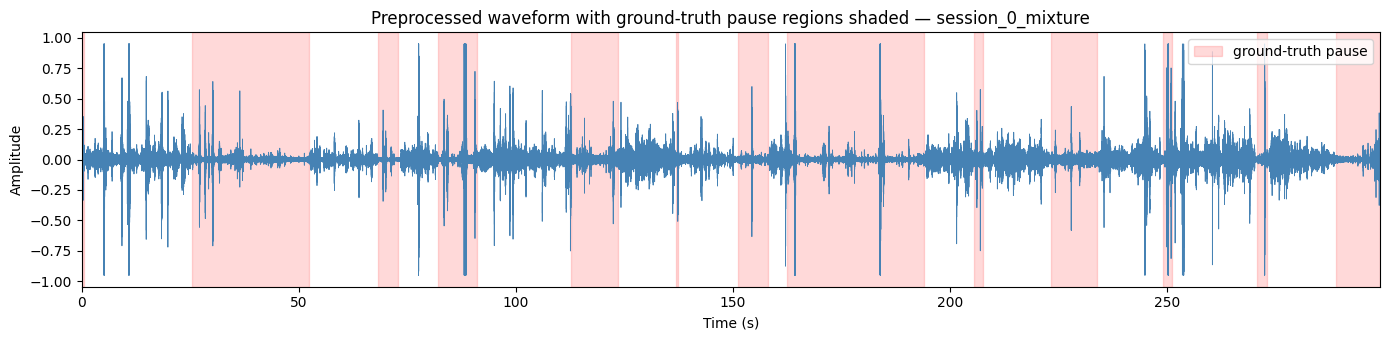

In [42]:
def shade_pauses(ax, frame_times, frame_labels, color="red", alpha=0.15, label="ground-truth pause"):
    '''Shade the x-axis wherever frame_labels == 0 (silence/pause),
    merging consecutive silent frames into one axvspan per pause so the
    legend gets one entry, not hundreds.'''
    in_pause, start, first = False, None, True
    for i, lab in enumerate(frame_labels):
        if lab == 0 and not in_pause:
            in_pause, start = True, frame_times[i]
        elif lab == 1 and in_pause:
            in_pause = False
            ax.axvspan(start, frame_times[i], color=color, alpha=alpha, label=label if first else None)
            first = False
    if in_pause:
        ax.axvspan(start, frame_times[-1], color=color, alpha=alpha, label=label if first else None)


fig, ax = plt.subplots(figsize=(14, 3.5))
sample_times = np.arange(len(audio)) / sr
ax.plot(sample_times, audio, linewidth=0.6, color="steelblue")
shade_pauses(ax, frame_times, frame_labels)
ax.set_title(f"Preprocessed waveform with ground-truth pause regions shaded — {session_label}")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Amplitude")
ax.set_xlim(0, duration)
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("plot_waveform.png", dpi=110)
plt.show()


## 3. Classical VAD features — short-time energy + zero-crossing rate

Both are computed per 25 ms frame / 10 ms hop, matching the frame grid set
up above:

- **Short-time energy** — RMS amplitude per frame, converted to dB. Speech
  frames sit well above the noise floor; pauses hover near it.
- **Zero-crossing rate (ZCR)** — how often the waveform's sign flips within
  a frame. Silence/low-energy noise: near-zero. Voiced speech: low-to-moderate
  (dominated by the fundamental frequency). Unvoiced/fricative speech: high.
  Energy alone can't tell fricatives from noise; ZCR gives the classical
  detector that second dimension.


In [43]:
def compute_short_time_energy(audio, frame_length=FRAME_LENGTH, hop_length=HOP_LENGTH):
    '''RMS energy per frame, in dB (relative to the loudest frame in
    this recording) so it's on a similar perceptual scale to the
    log-mel features below.'''
    rms = librosa.feature.rms(y=audio, frame_length=frame_length, hop_length=hop_length, center=False)[0]
    return librosa.amplitude_to_db(rms, ref=np.max)


def compute_zcr(audio, frame_length=FRAME_LENGTH, hop_length=HOP_LENGTH):
    '''Fraction of sign-changes per frame.'''
    return librosa.feature.zero_crossing_rate(y=audio, frame_length=frame_length, hop_length=hop_length, center=False)[0]


energy_db = compute_short_time_energy(audio)
zcr = compute_zcr(audio)

assert len(energy_db) == len(zcr) == n_frames, "energy/ZCR frame count doesn't match ground-truth labels"
print(f"energy_db shape: {energy_db.shape}")
print(f"zcr shape      : {zcr.shape}")


energy_db shape: (29896,)
zcr shape      : (29896,)


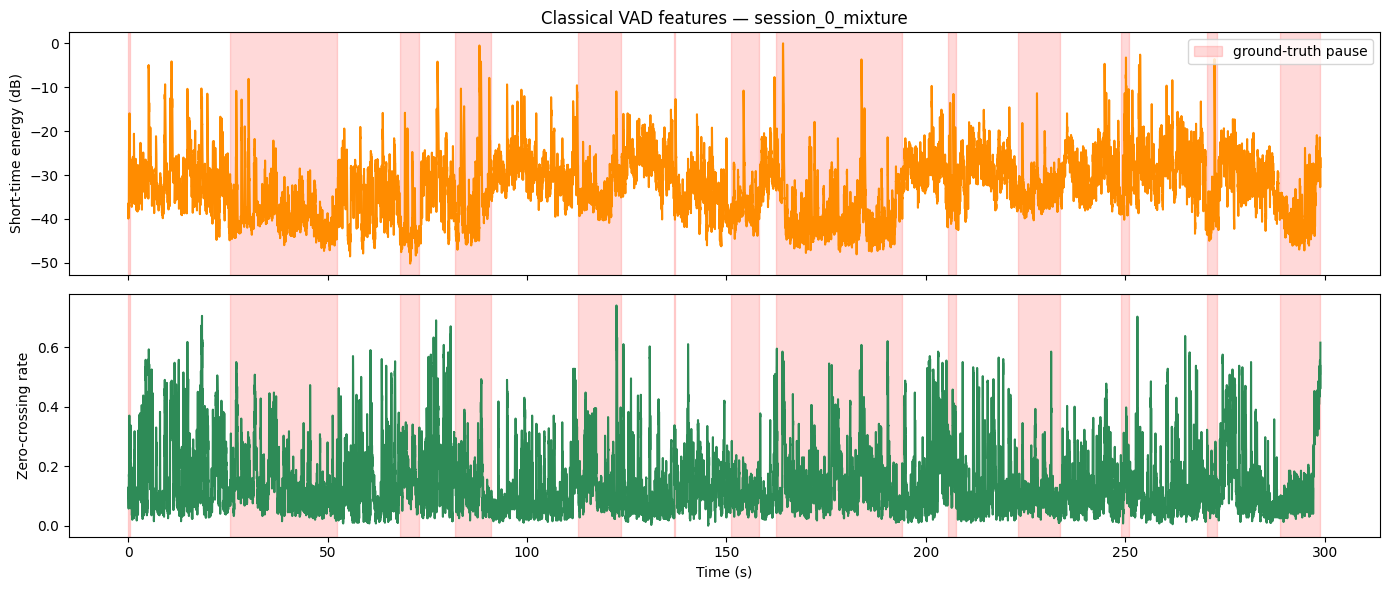

In [44]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

axes[0].plot(frame_times, energy_db, color="darkorange")
shade_pauses(axes[0], frame_times, frame_labels)
axes[0].set_ylabel("Short-time energy (dB)")
axes[0].set_title(f"Classical VAD features — {session_label}")
axes[0].legend(loc="upper right")

axes[1].plot(frame_times, zcr, color="seagreen")
shade_pauses(axes[1], frame_times, frame_labels)
axes[1].set_ylabel("Zero-crossing rate")
axes[1].set_xlabel("Time (s)")

plt.tight_layout()
plt.savefig("plot_classical_features.png", dpi=110)
plt.show()


## 4. Neural VAD features — log-mel spectrogram

The CRNN takes a log-mel spectrogram: `n_fft` here is deliberately set
**equal to the 25 ms frame length** (400 samples at 16 kHz) rather than the
usual 512/1024, purely so this branch lands on **exactly the same frame
grid** as the energy/ZCR features and the ground-truth labels — that
alignment is what makes frame-by-frame benchmarking (and later, a fused
model) straightforward.

Features are also mean/variance normalized per utterance before being fed
to a network — standard practice that stabilizes training.


In [45]:
def compute_log_mel_spectrogram(audio, sr=SAMPLE_RATE, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS):
    '''Log-mel spectrogram, shape (n_mels, n_frames). n_fft == FRAME_LENGTH
    so n_frames matches the classical branch exactly.'''
    mel = librosa.feature.melspectrogram(y=audio, sr=sr, n_fft=n_fft, hop_length=hop_length,
                                          win_length=n_fft, n_mels=n_mels, center=False, power=2.0)
    return librosa.power_to_db(mel, ref=np.max)


def normalize_features(feat):
    '''Zero-mean, unit-variance per feature dimension — standard
    pre-processing before feeding spectrogram frames into a neural net.'''
    mean = feat.mean(axis=1, keepdims=True)
    std = feat.std(axis=1, keepdims=True) + 1e-9
    return (feat - mean) / std


log_mel = compute_log_mel_spectrogram(audio)
log_mel_norm = normalize_features(log_mel)

assert log_mel.shape[1] == n_frames, "mel-spectrogram frame count doesn't match — check n_fft/hop_length"
print(f"log_mel shape: {log_mel.shape}  (n_mels, n_frames)")


log_mel shape: (40, 29896)  (n_mels, n_frames)


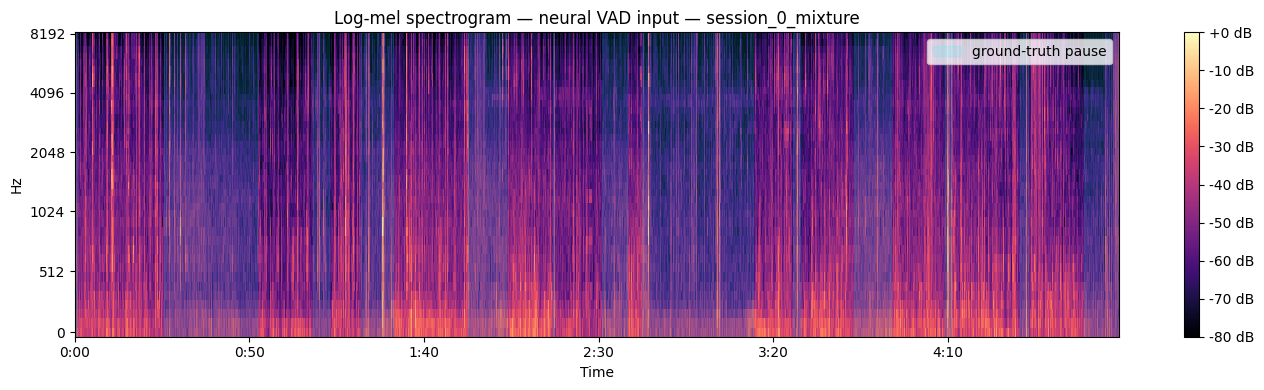

In [46]:
fig, ax = plt.subplots(figsize=(14, 4))
img = librosa.display.specshow(log_mel, sr=sr, hop_length=HOP_LENGTH, x_axis="time", y_axis="mel", ax=ax, cmap="magma")
shade_pauses(ax, frame_times, frame_labels, color="cyan", alpha=0.12)
ax.set_title(f"Log-mel spectrogram — neural VAD input — {session_label}")
fig.colorbar(img, ax=ax, format="%+2.0f dB")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("plot_melspectrogram.png", dpi=110)
plt.show()


## 5. Alignment sanity check

Both branches must produce the *same number of frames* as the ground-truth
label array — the assertions above already confirm this, but the combined
figure below is the clearest way to see it (and a good single image to show
your professor as progress evidence): waveform, classical features, and the
neural input all stacked on one shared time axis, with the same pause
regions shaded throughout.


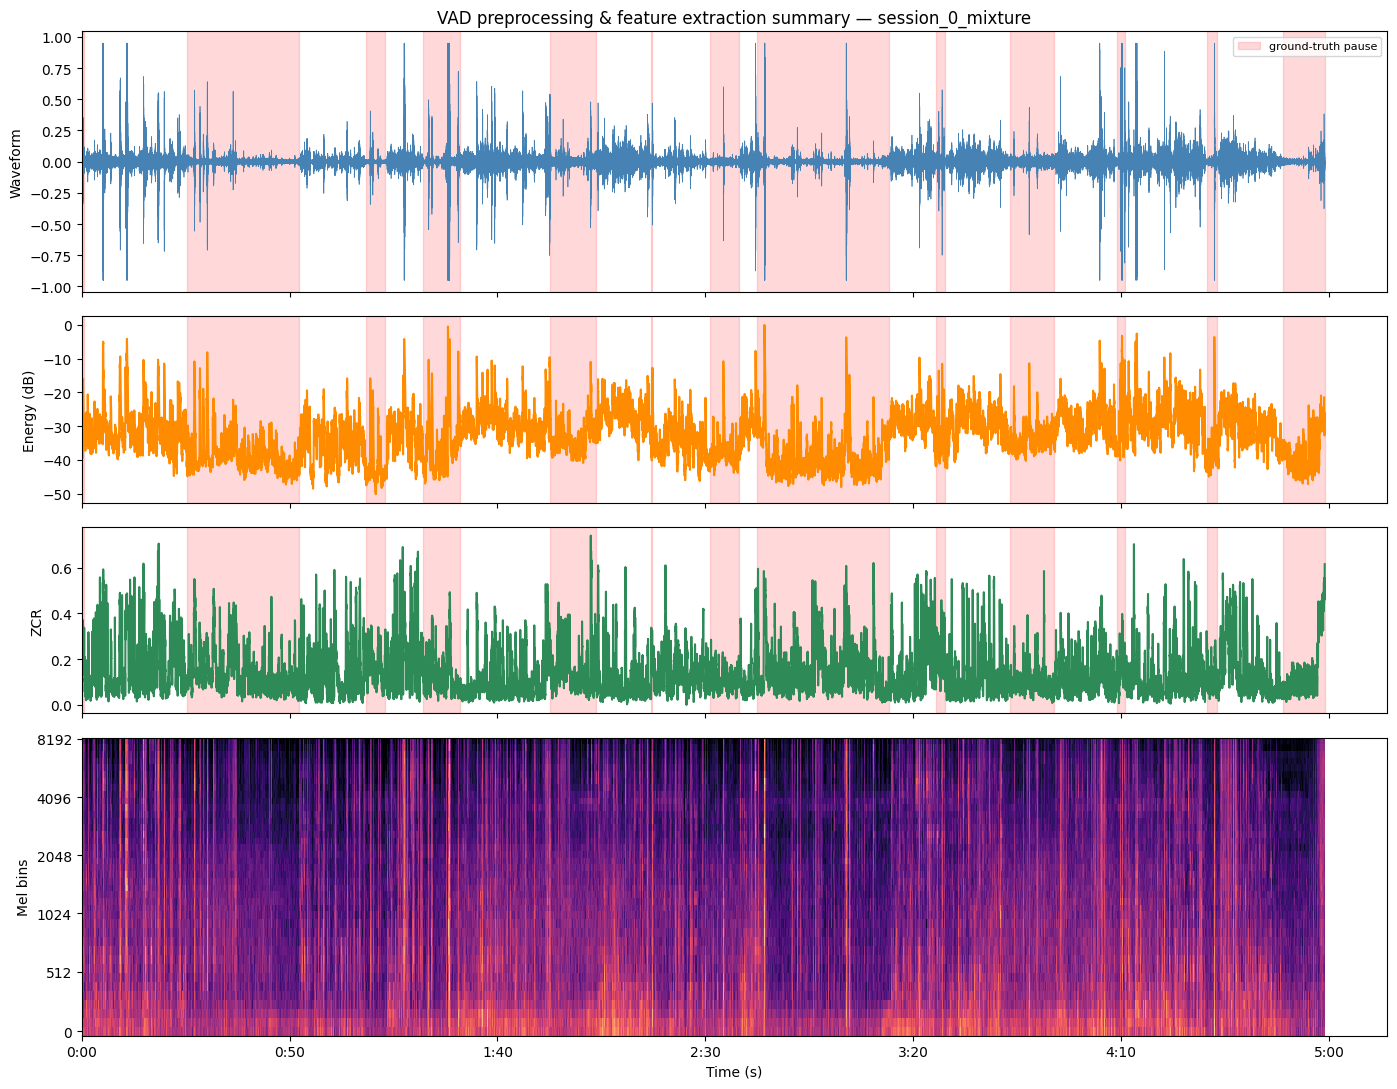

Frame counts — energy: 29896  zcr: 29896  mel: 29896  ground_truth: 29896  (all equal ✓)


In [47]:
fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True,
                          gridspec_kw={"height_ratios": [1.4, 1, 1, 1.6]})

axes[0].plot(sample_times, audio, linewidth=0.5, color="steelblue")
shade_pauses(axes[0], frame_times, frame_labels)
axes[0].set_ylabel("Waveform")
axes[0].set_title(f"VAD preprocessing & feature extraction summary — {session_label}")
axes[0].legend(loc="upper right", fontsize=8)

axes[1].plot(frame_times, energy_db, color="darkorange")
shade_pauses(axes[1], frame_times, frame_labels)
axes[1].set_ylabel("Energy (dB)")

axes[2].plot(frame_times, zcr, color="seagreen")
shade_pauses(axes[2], frame_times, frame_labels)
axes[2].set_ylabel("ZCR")

librosa.display.specshow(log_mel, sr=sr, hop_length=HOP_LENGTH, x_axis="time", y_axis="mel", ax=axes[3], cmap="magma")
axes[3].set_ylabel("Mel bins")
axes[3].set_xlabel("Time (s)")

plt.tight_layout()
plt.savefig("plot_combined_summary.png", dpi=120)
plt.show()

print("Frame counts — energy:", len(energy_db), " zcr:", len(zcr),
      " mel:", log_mel.shape[1], " ground_truth:", len(frame_labels), " (all equal ✓)")


## 6. Caching features to disk

Feature extraction (especially the mel-spectrogram, over a full corpus) is
worth computing once and reusing — the next notebook (model training)
should load straight from these `.npz` files instead of recomputing.


In [48]:
os.makedirs("features", exist_ok=True)
out_path = os.path.join("features", f"{session_tag}_features.npz")
np.savez(out_path,
         energy_db=energy_db, zcr=zcr,
         log_mel=log_mel, log_mel_norm=log_mel_norm,
         frame_labels=frame_labels, frame_times=frame_times,
         sr=sr, hop_length=HOP_LENGTH, frame_length=FRAME_LENGTH)
print(f"Saved: {out_path}")
print("Keys :", list(np.load(out_path).keys()))


Saved: features/session_0_mixture_features.npz
Keys : ['energy_db', 'zcr', 'log_mel', 'log_mel_norm', 'frame_labels', 'frame_times', 'sr', 'hop_length', 'frame_length']


## 7. Scaling up to the full corpus

Once the full LibriParty corpus is downloaded, `process_session()` ties
everything above into one call per session; the (commented-out) loop below
shows how you'd run it over an entire split.


In [49]:
def process_session(wav_path, json_path, out_dir="features"):
    '''Load, preprocess, and extract both feature sets for one session,
    caching the result to <out_dir>/<session_name>_features.npz. Call this
    once per session when running over the real corpus.'''
    audio_, sr_, speech_segments_ = load_libriparty_session(wav_path, json_path)
    audio_ = peak_normalize(audio_)

    n_frames_ = 1 + (len(audio_) - FRAME_LENGTH) // HOP_LENGTH
    labels_, times_ = segments_to_frame_labels(speech_segments_, n_frames_, sr_)

    energy_ = compute_short_time_energy(audio_)
    zcr_ = compute_zcr(audio_)
    mel_ = compute_log_mel_spectrogram(audio_, sr=sr_)
    mel_norm_ = normalize_features(mel_)

    os.makedirs(out_dir, exist_ok=True)
    name = os.path.splitext(os.path.basename(wav_path))[0]
    np.savez(os.path.join(out_dir, f"{name}_features.npz"),
             energy_db=energy_, zcr=zcr_, log_mel=mel_, log_mel_norm=mel_norm_,
             frame_labels=labels_, frame_times=times_, sr=sr_,
             hop_length=HOP_LENGTH, frame_length=FRAME_LENGTH)
    return name


# Process every real audio session. Plots are generated only by the earlier
# single-session analysis cells for train/session_0.
DATASET_ROOT = "LibriParty/dataset"
DATASET_SPLITS = ["train", "dev", "eval"]
processed_count = 0

for split_name in DATASET_SPLITS:
    split_dir = os.path.join(DATASET_ROOT, split_name)
    split_out_dir = os.path.join("features", split_name)
    session_dirs = sorted(glob.glob(os.path.join(split_dir, "session_*")))

    for session_dir in session_dirs:
        session_name = os.path.basename(session_dir)
        split_wavs = sorted(glob.glob(os.path.join(session_dir, "*_mixture.wav")))
        json_path = os.path.join(session_dir, f"{session_name}.json")

        for wav_path in split_wavs:
            name = process_session(wav_path, json_path, out_dir=split_out_dir)
            processed_count += 1
            print(f"processed: {split_name}/{name}")

print(f"Total sessions processed: {processed_count}")

processed: train/session_0_mixture
processed: train/session_1_mixture
processed: train/session_10_mixture
processed: train/session_100_mixture
processed: train/session_101_mixture
processed: train/session_102_mixture
processed: train/session_103_mixture
processed: train/session_104_mixture
processed: train/session_105_mixture
processed: train/session_106_mixture
processed: train/session_107_mixture
processed: train/session_108_mixture
processed: train/session_109_mixture
processed: train/session_11_mixture
processed: train/session_110_mixture
processed: train/session_111_mixture
processed: train/session_112_mixture
processed: train/session_113_mixture
processed: train/session_114_mixture
processed: train/session_115_mixture
processed: train/session_116_mixture
processed: train/session_117_mixture
processed: train/session_118_mixture
processed: train/session_119_mixture
processed: train/session_12_mixture
processed: train/session_120_mixture
processed: train/session_121_mixture
processe

## Next steps (not in this notebook)

With features cached, the next notebook covers:

1. Train the **CRNN neural VAD** (binary cross-entropy on `log_mel_norm` vs. `frame_labels`).
2. Calibrate the **classical baseline**'s energy/ZCR thresholds against a small dev set.
3. Apply **hysteresis smoothing → segment merging → pause classification** to each model's raw frame output.
4. **Benchmark** classical vs. neural vs. Silero VAD with precision/recall/F1 against `frame_labels`.
